In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"banothuthirupathi","key":"ab9ad3df6d23dff44a9fa64cdc1929cc"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d sebastianpalaciob/tomato-leaf-diseases-dataset-for-object-detection

Dataset URL: https://www.kaggle.com/datasets/sebastianpalaciob/tomato-leaf-diseases-dataset-for-object-detection
License(s): CC-BY-NC-SA-4.0
100% 835M/835M [00:12<00:00, 68.0MB/s]



In [ ]:
import zipfile

with zipfile.ZipFile(
    "/content/tomato-leaf-diseases-dataset-for-object-detection.zip",
    "r"
) as zip_ref:
    zip_ref.extractall("/content/tomato_detection")

In [ ]:
import os

for root, dirs, files in os.walk("/content/tomato_detection"):
    print(root)

/content/tomato_detection
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/valid
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/valid/images
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/valid/labels
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/train
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/train/images
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/train/labels
/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset with augmentation/test
/content/toma

In [ ]:
import os

dataset_path = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation"

for file in os.listdir(dataset_path):
    print(file)

valid
train
README.roboflow.txt
README.dataset.txt
test
data.yaml


In [ ]:
import os

train_images = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/train/images"
train_labels = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/train/labels"

print("Train Images:", len(os.listdir(train_images)))
print("Train Labels:", len(os.listdir(train_labels)))

Train Images: 3244
Train Labels: 3244


In [ ]:
valid_images = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/valid/images"
valid_labels = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/valid/labels"

print("Validation Images:", len(os.listdir(valid_images)))
print("Validation Labels:", len(os.listdir(valid_labels)))

Validation Images: 659
Validation Labels: 659


In [ ]:
test_images = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/test/images"
test_labels = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/test/labels"

print("Test Images:", len(os.listdir(test_images)))
print("Test Labels:", len(os.listdir(test_labels)))

Test Images: 420
Test Labels: 420


In [ ]:
data_yaml = "/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/data.yaml"

with open(data_yaml, "r") as f:
    print(f.read())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 9
names: ['Early Blight', 'Healthy', 'Late Blight', 'Leaf Miner', 'Leaf Mold', 'Mosaic Virus', 'Septoria', 'Spider Mites', 'Yellow Leaf Curl Virus']

roboflow:
  workspace: tdg-cikuh
  project: tdg-vq3xp
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/tdg-cikuh/tdg-vq3xp/dataset/1


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.3 MB/s eta 0:00:00


In [ ]:
import ultralytics
print(ultralytics.__version__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
8.4.77


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
print("YOLO loaded successfully!")

YOLO loaded successfully!


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano Detection model
model = YOLO("yolov8n.pt")

# Train the model
results = model.train(
    data="/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    workers=2,
    project="/content/yolo_runs",
    name="tomato_detection",
    pretrained=True
)

Ultralytics 8.4.77 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/tomato_detection/Tomato leaf diseases dataset for Object Detection/Dataset without augmentation/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scal

In [ ]:
!ls /content/yolo_runs/tomato_detection

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg     val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch8120.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch8121.jpg  weights
labels.jpg			 train_batch8122.jpg


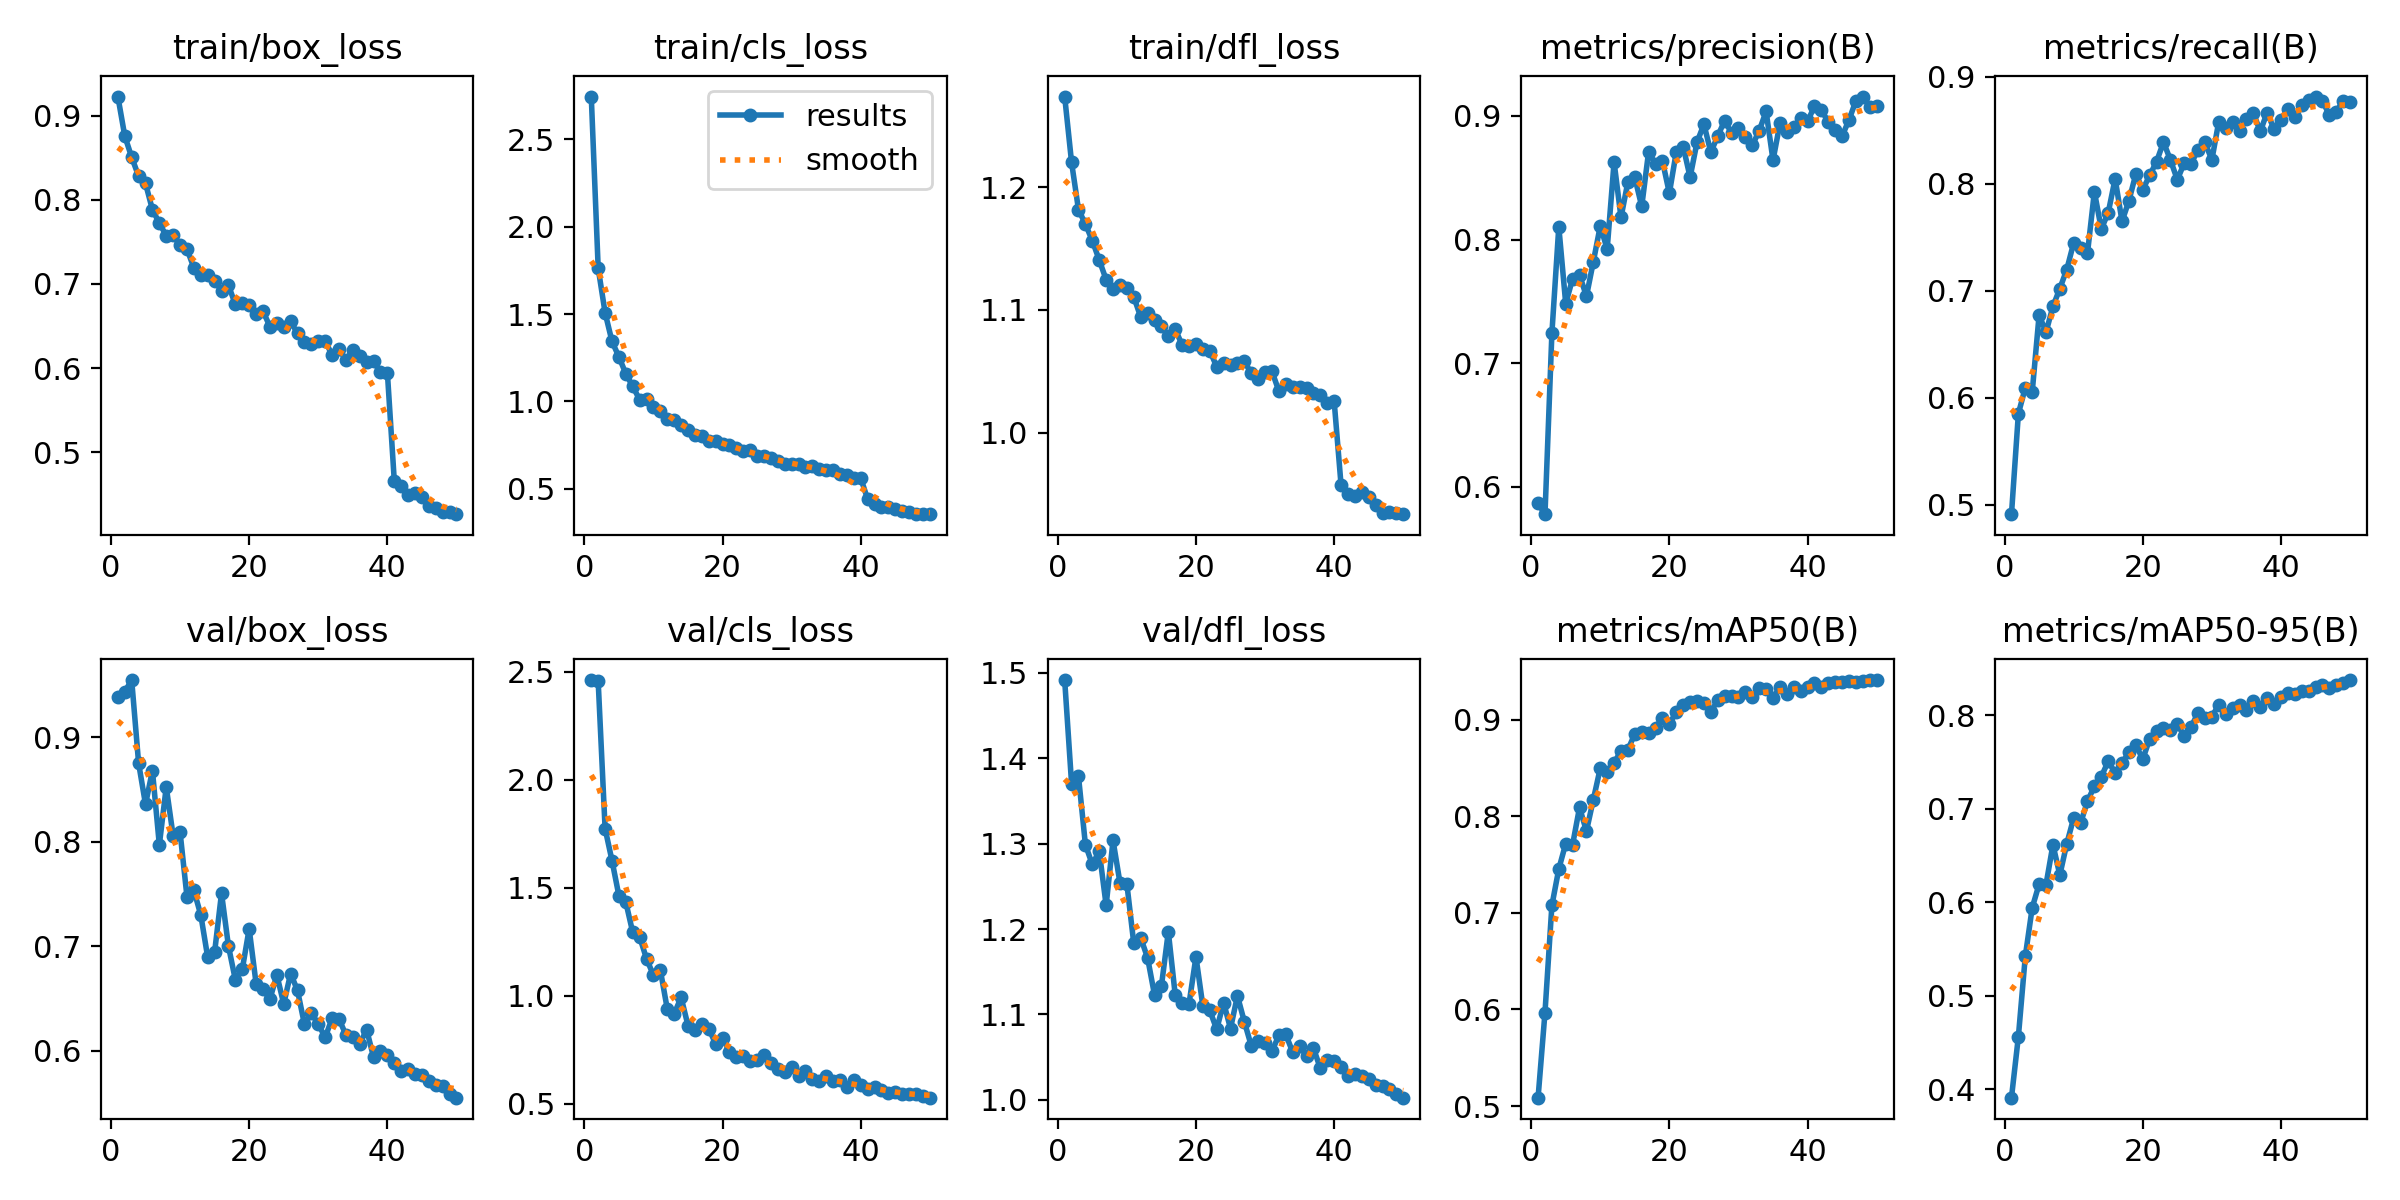

In [ ]:
from IPython.display import Image

Image("/content/yolo_runs/tomato_detection/results.png")

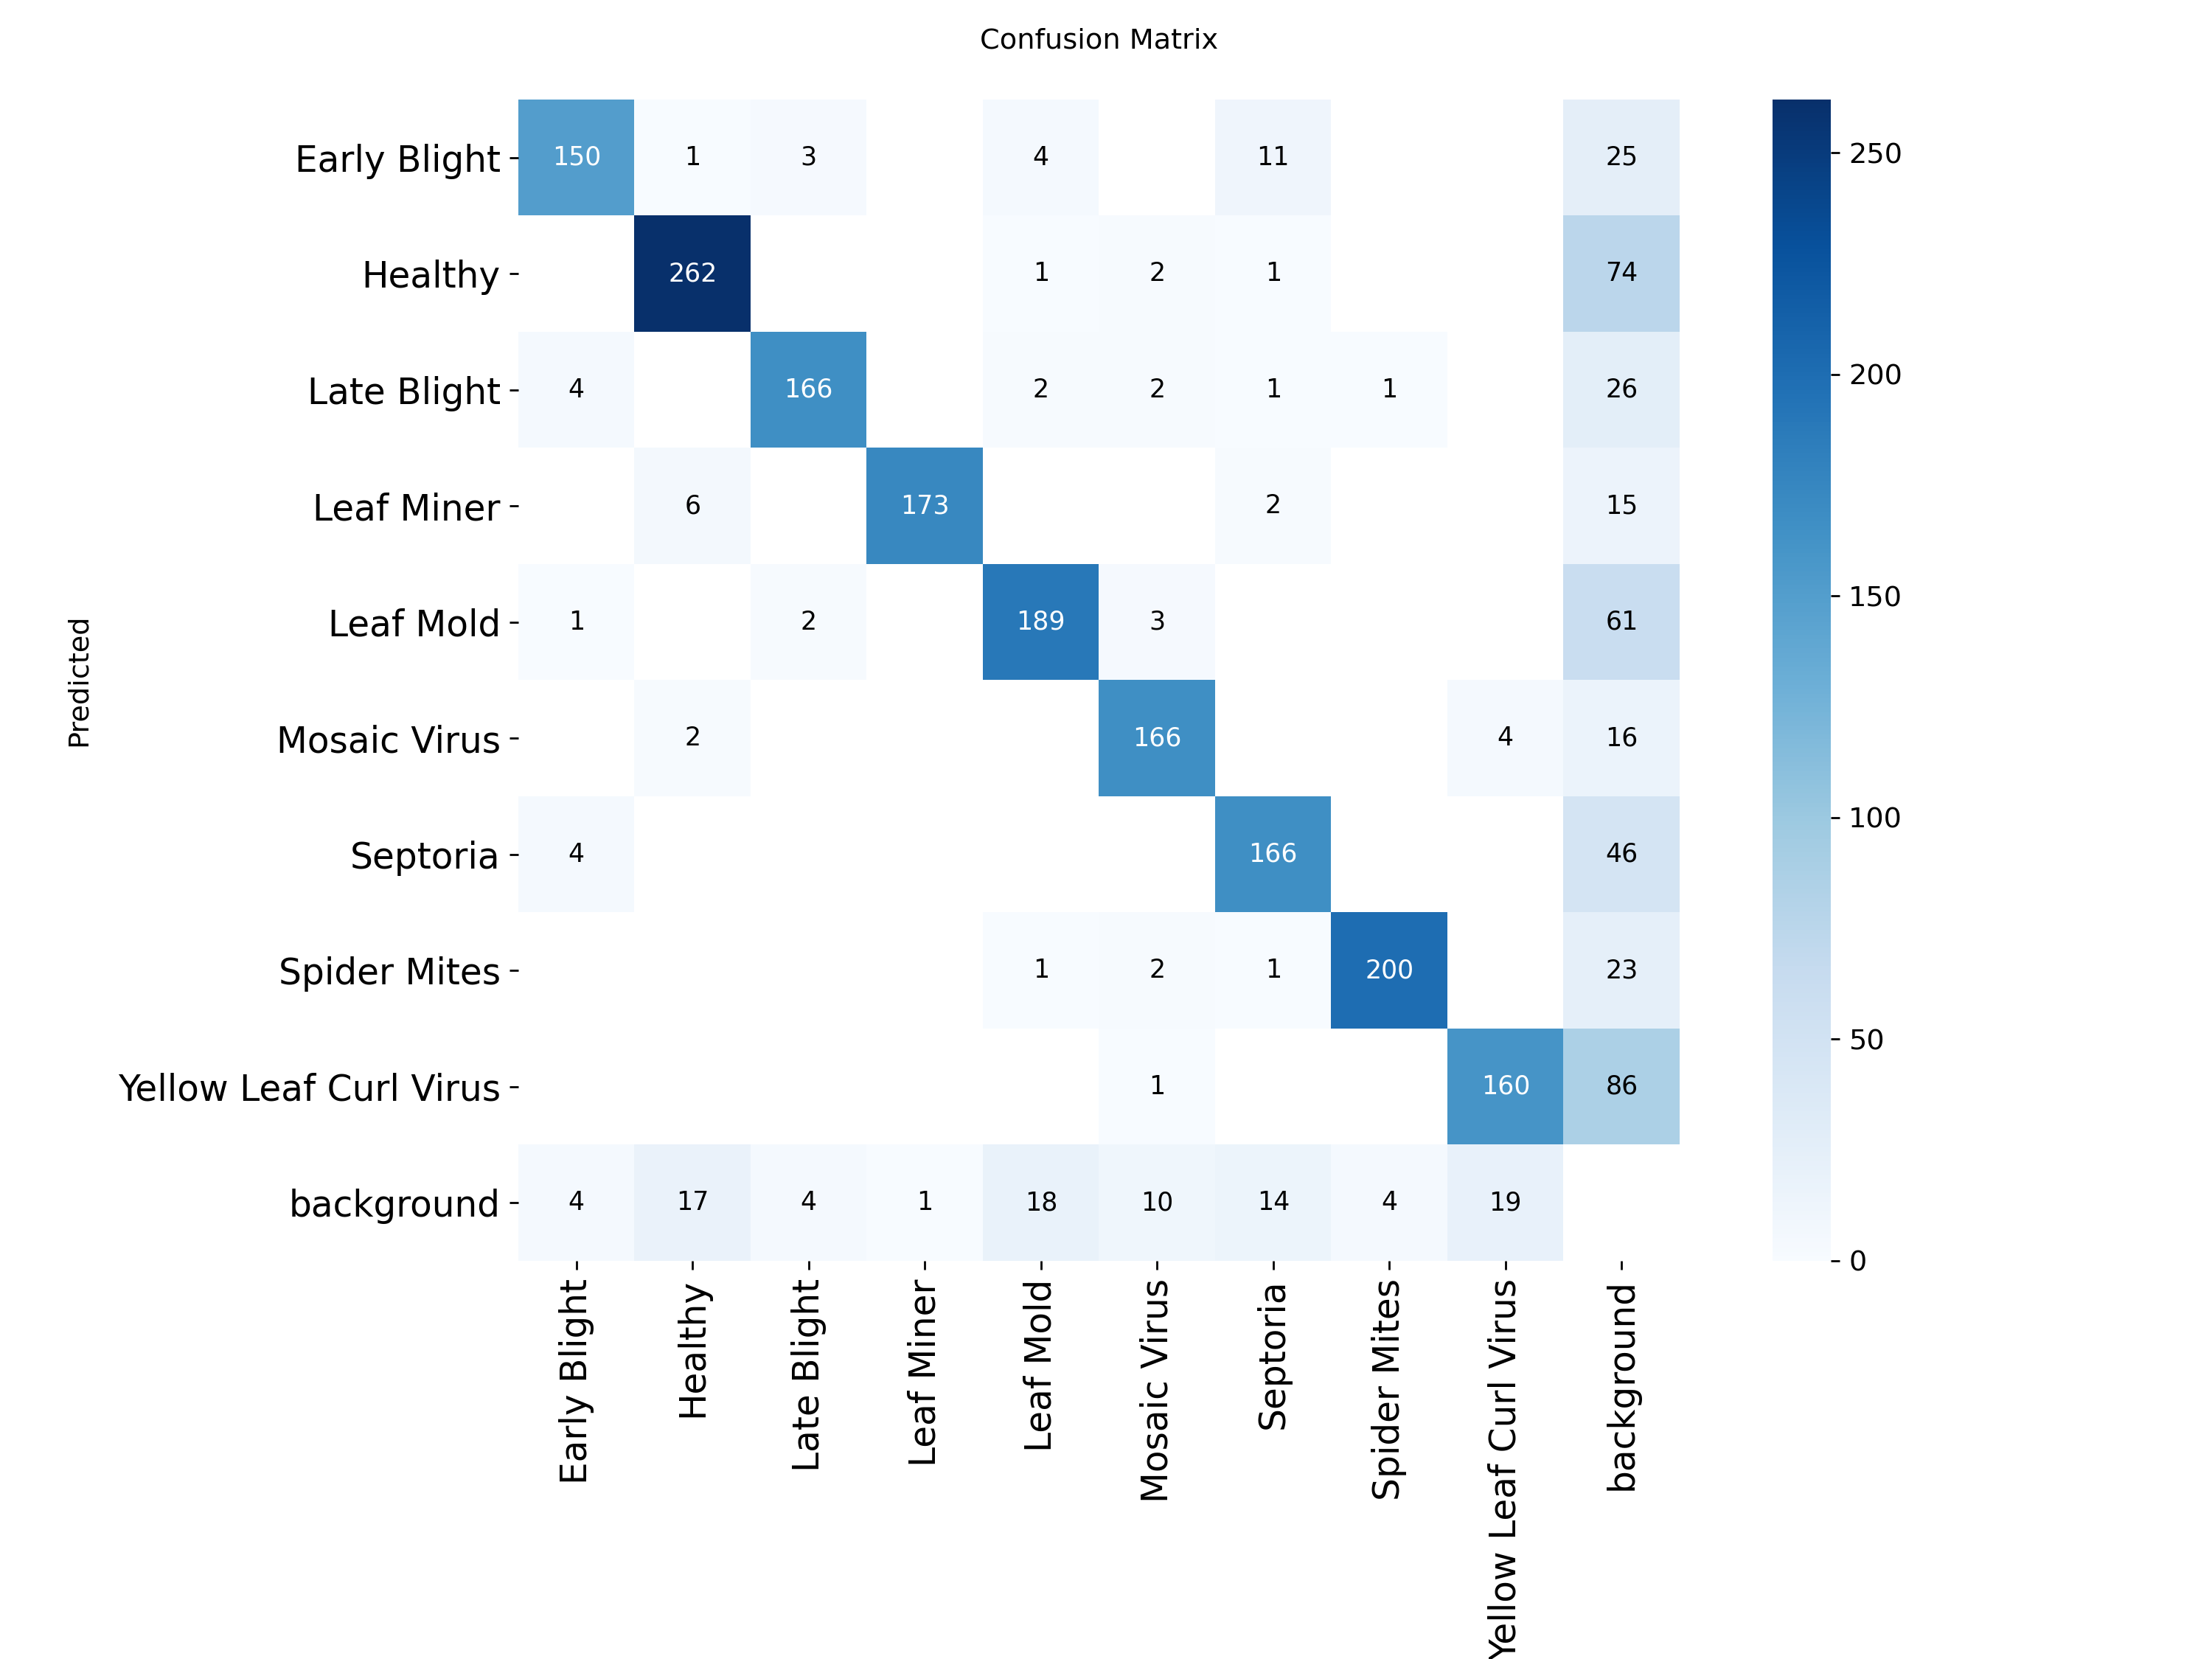

In [ ]:
Image("/content/yolo_runs/tomato_detection/confusion_matrix.png")

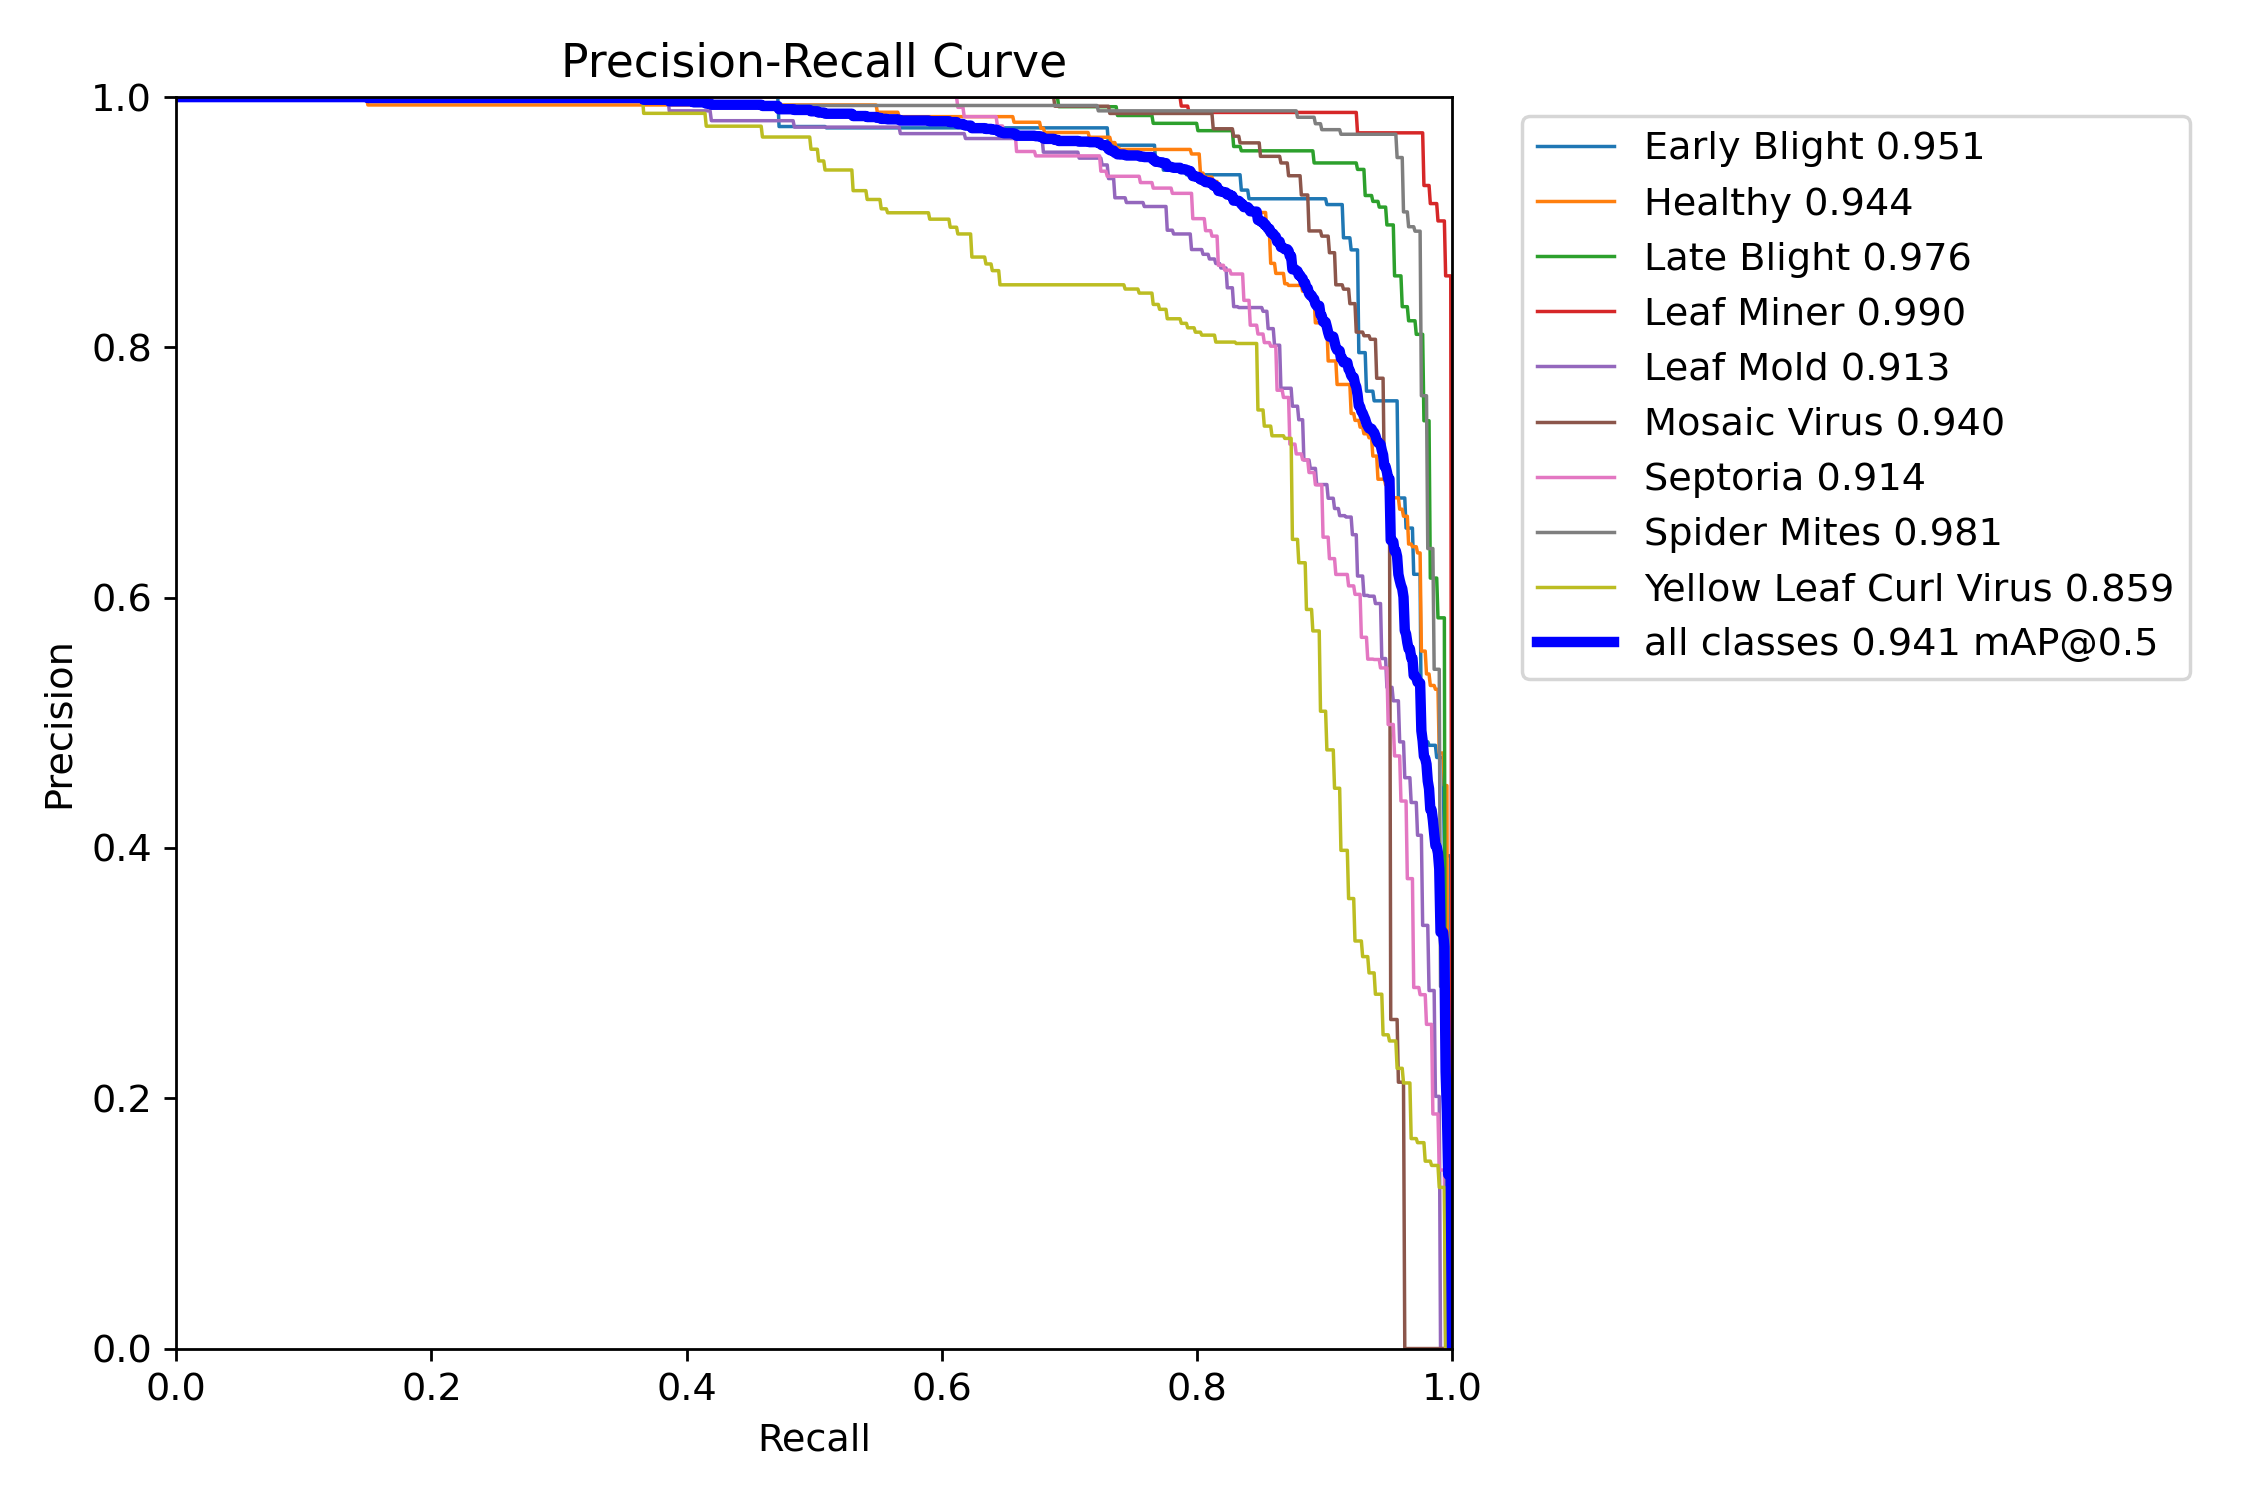

In [ ]:
Image("/content/yolo_runs/tomato_detection/BoxPR_curve.png")

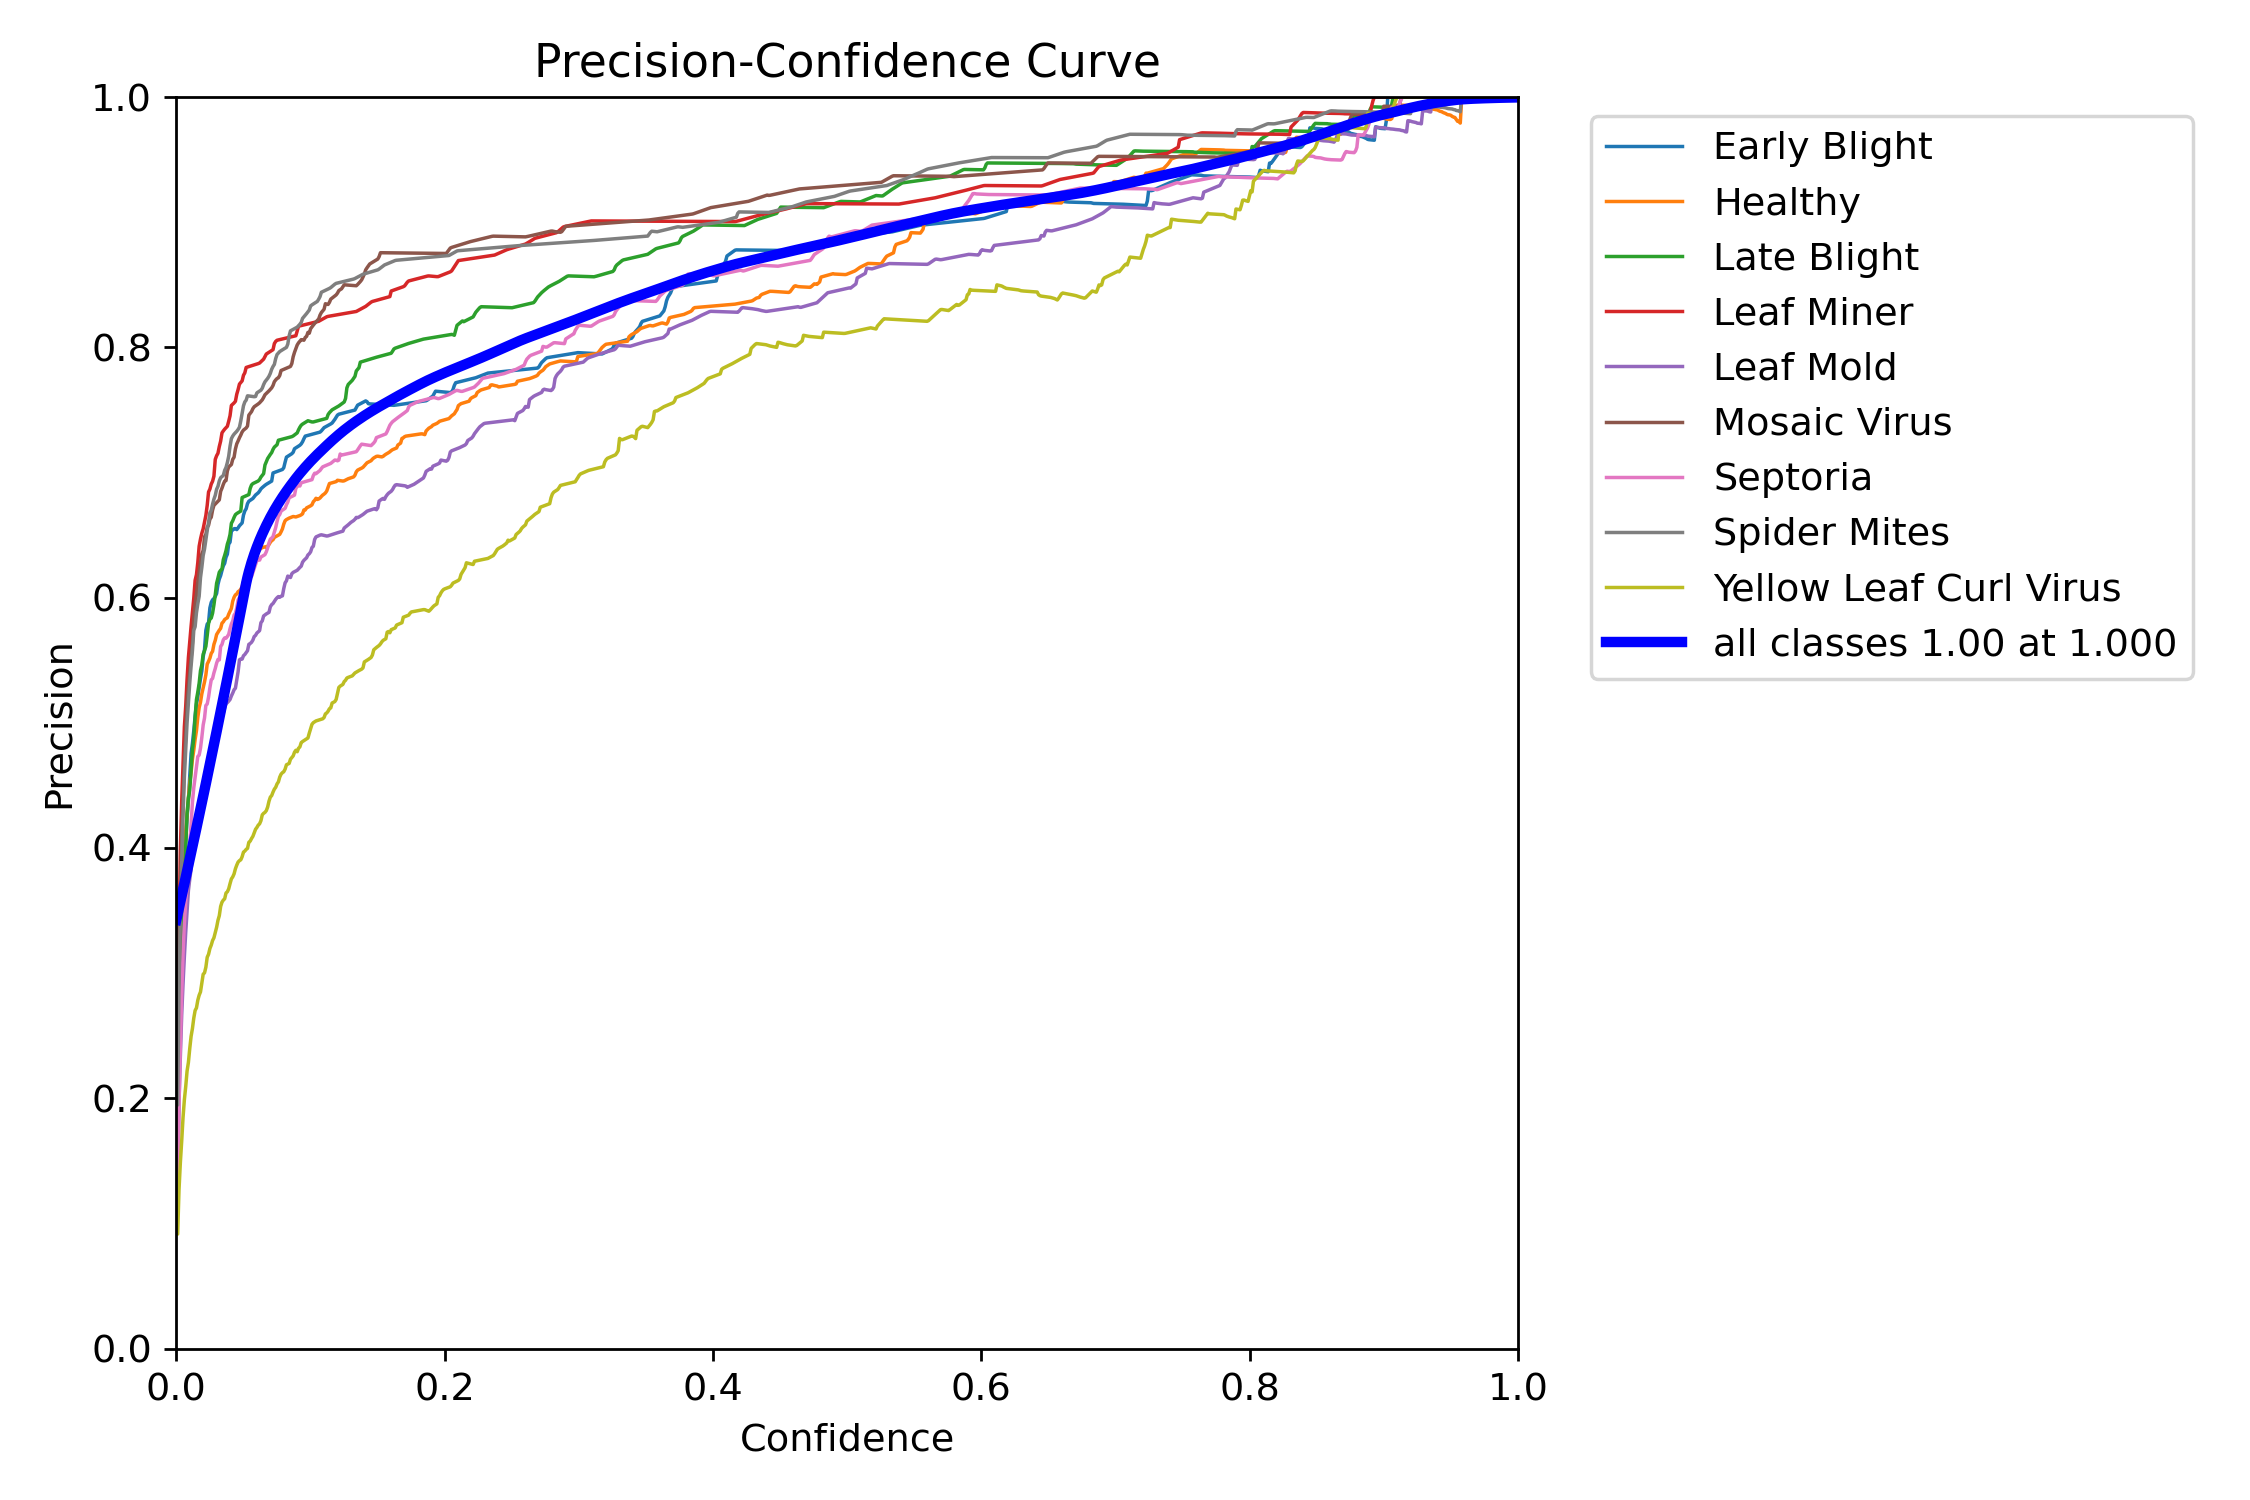

In [ ]:
Image("/content/yolo_runs/tomato_detection/BoxP_curve.png")

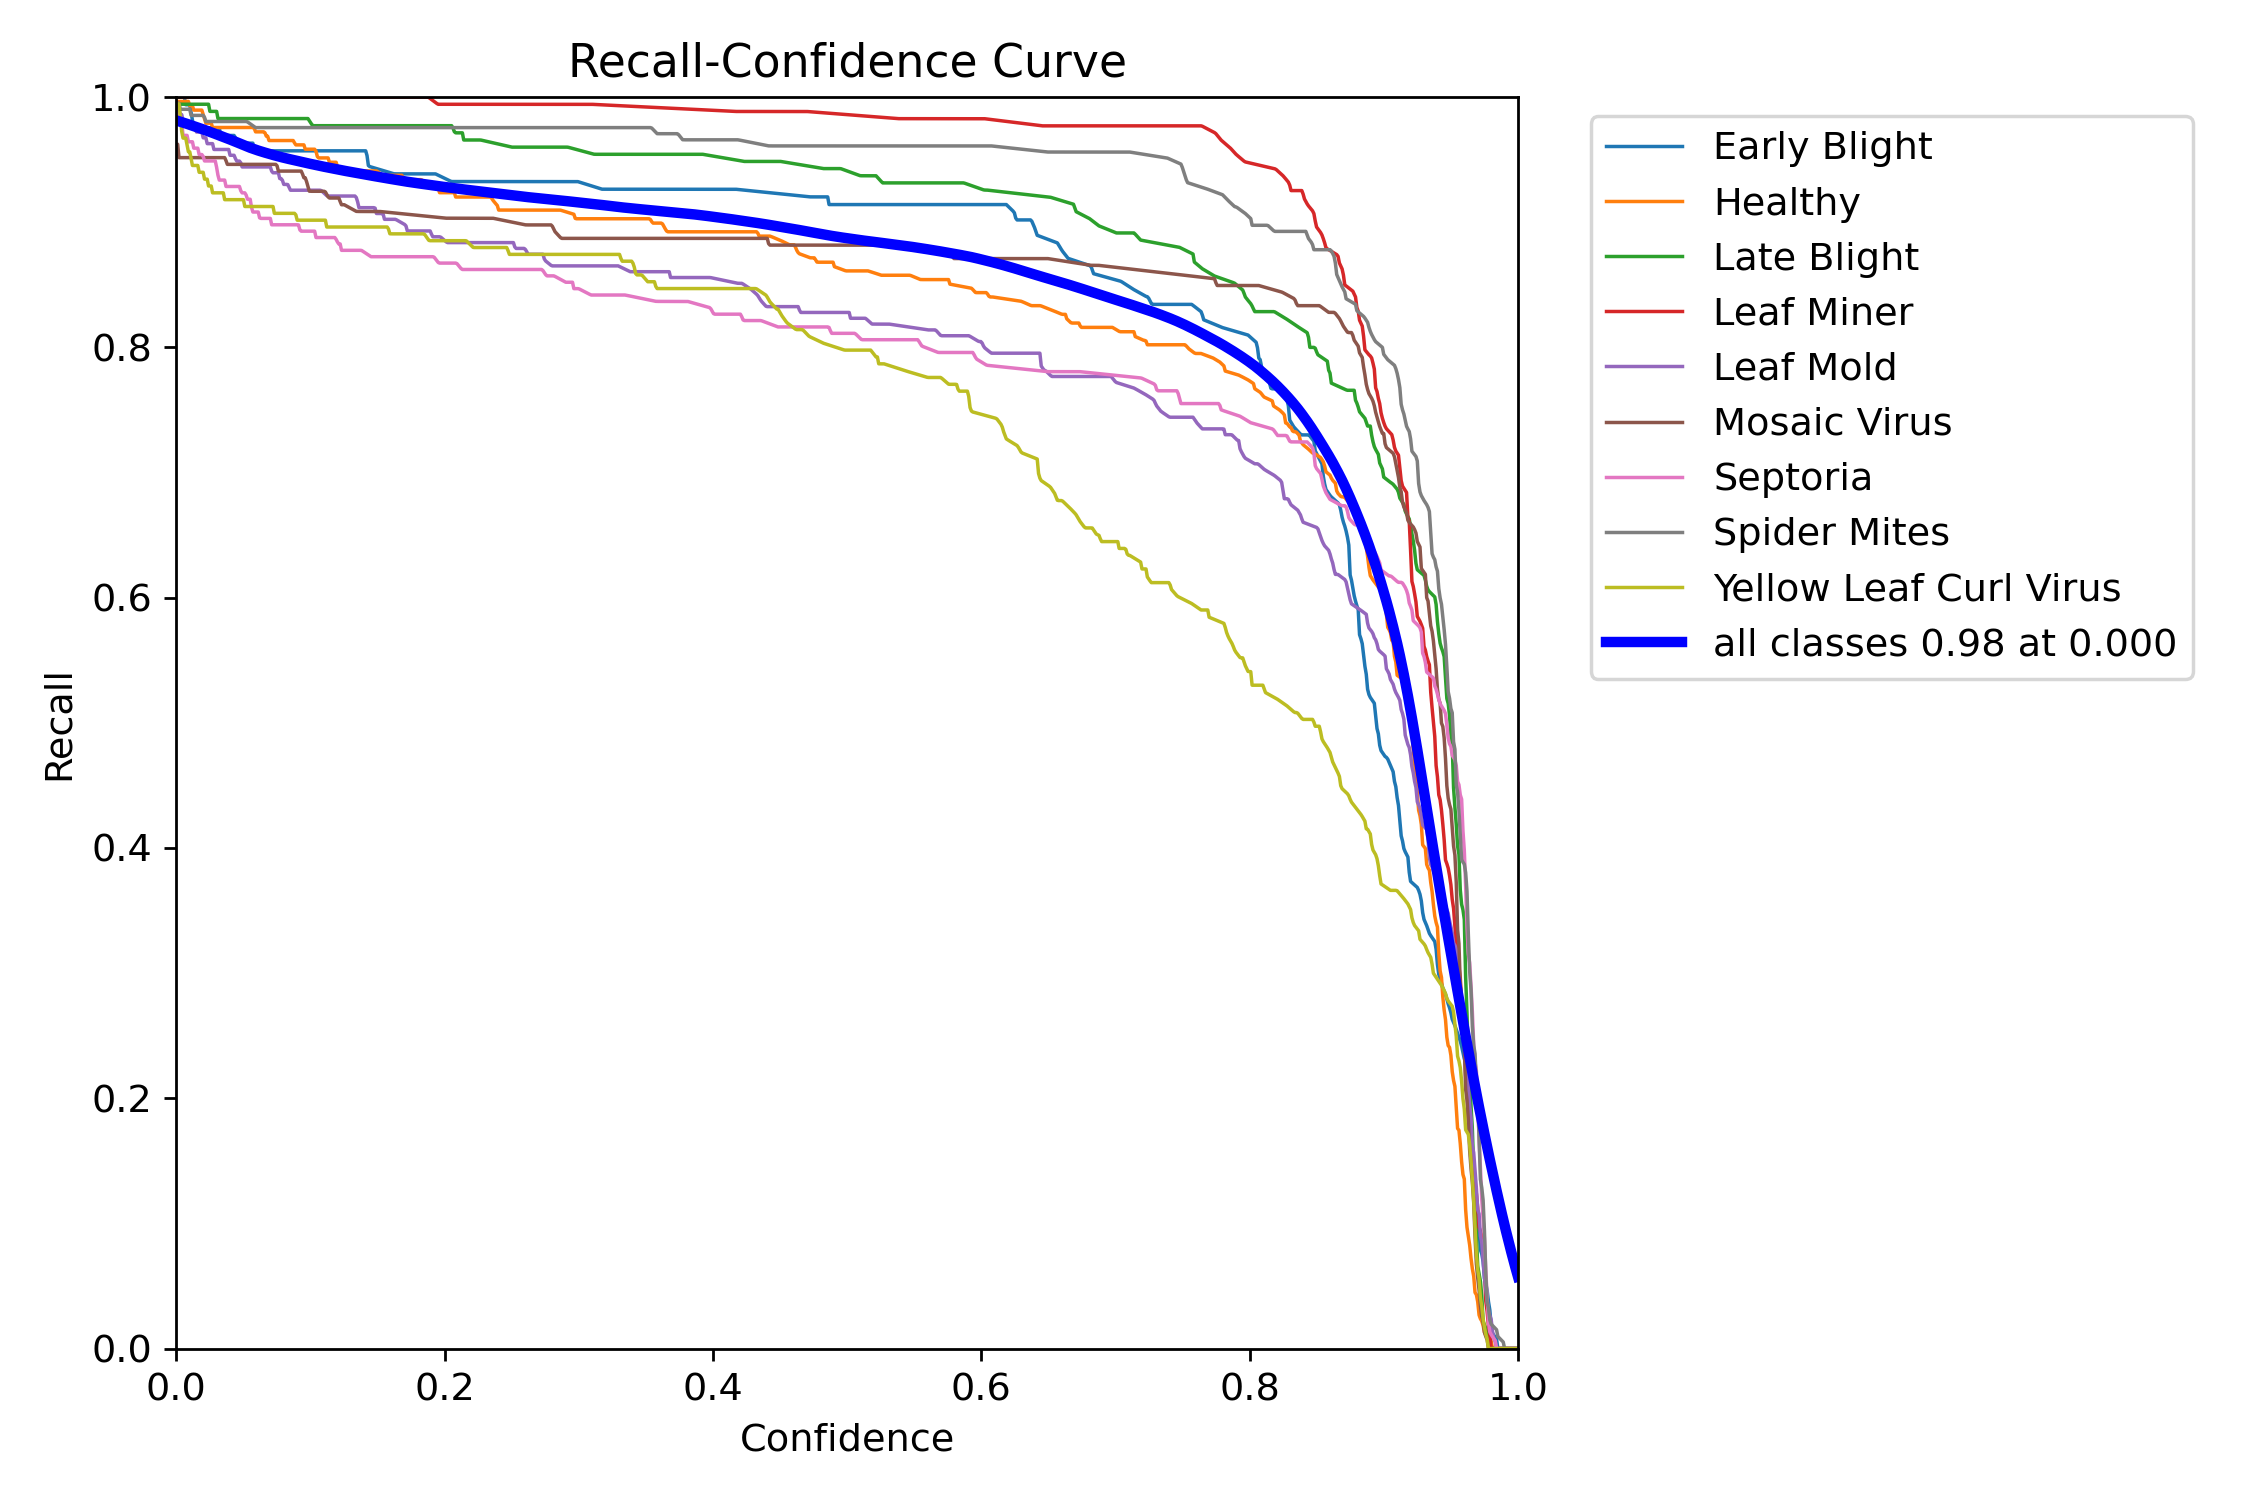

In [ ]:
Image("/content/yolo_runs/tomato_detection/BoxR_curve.png")

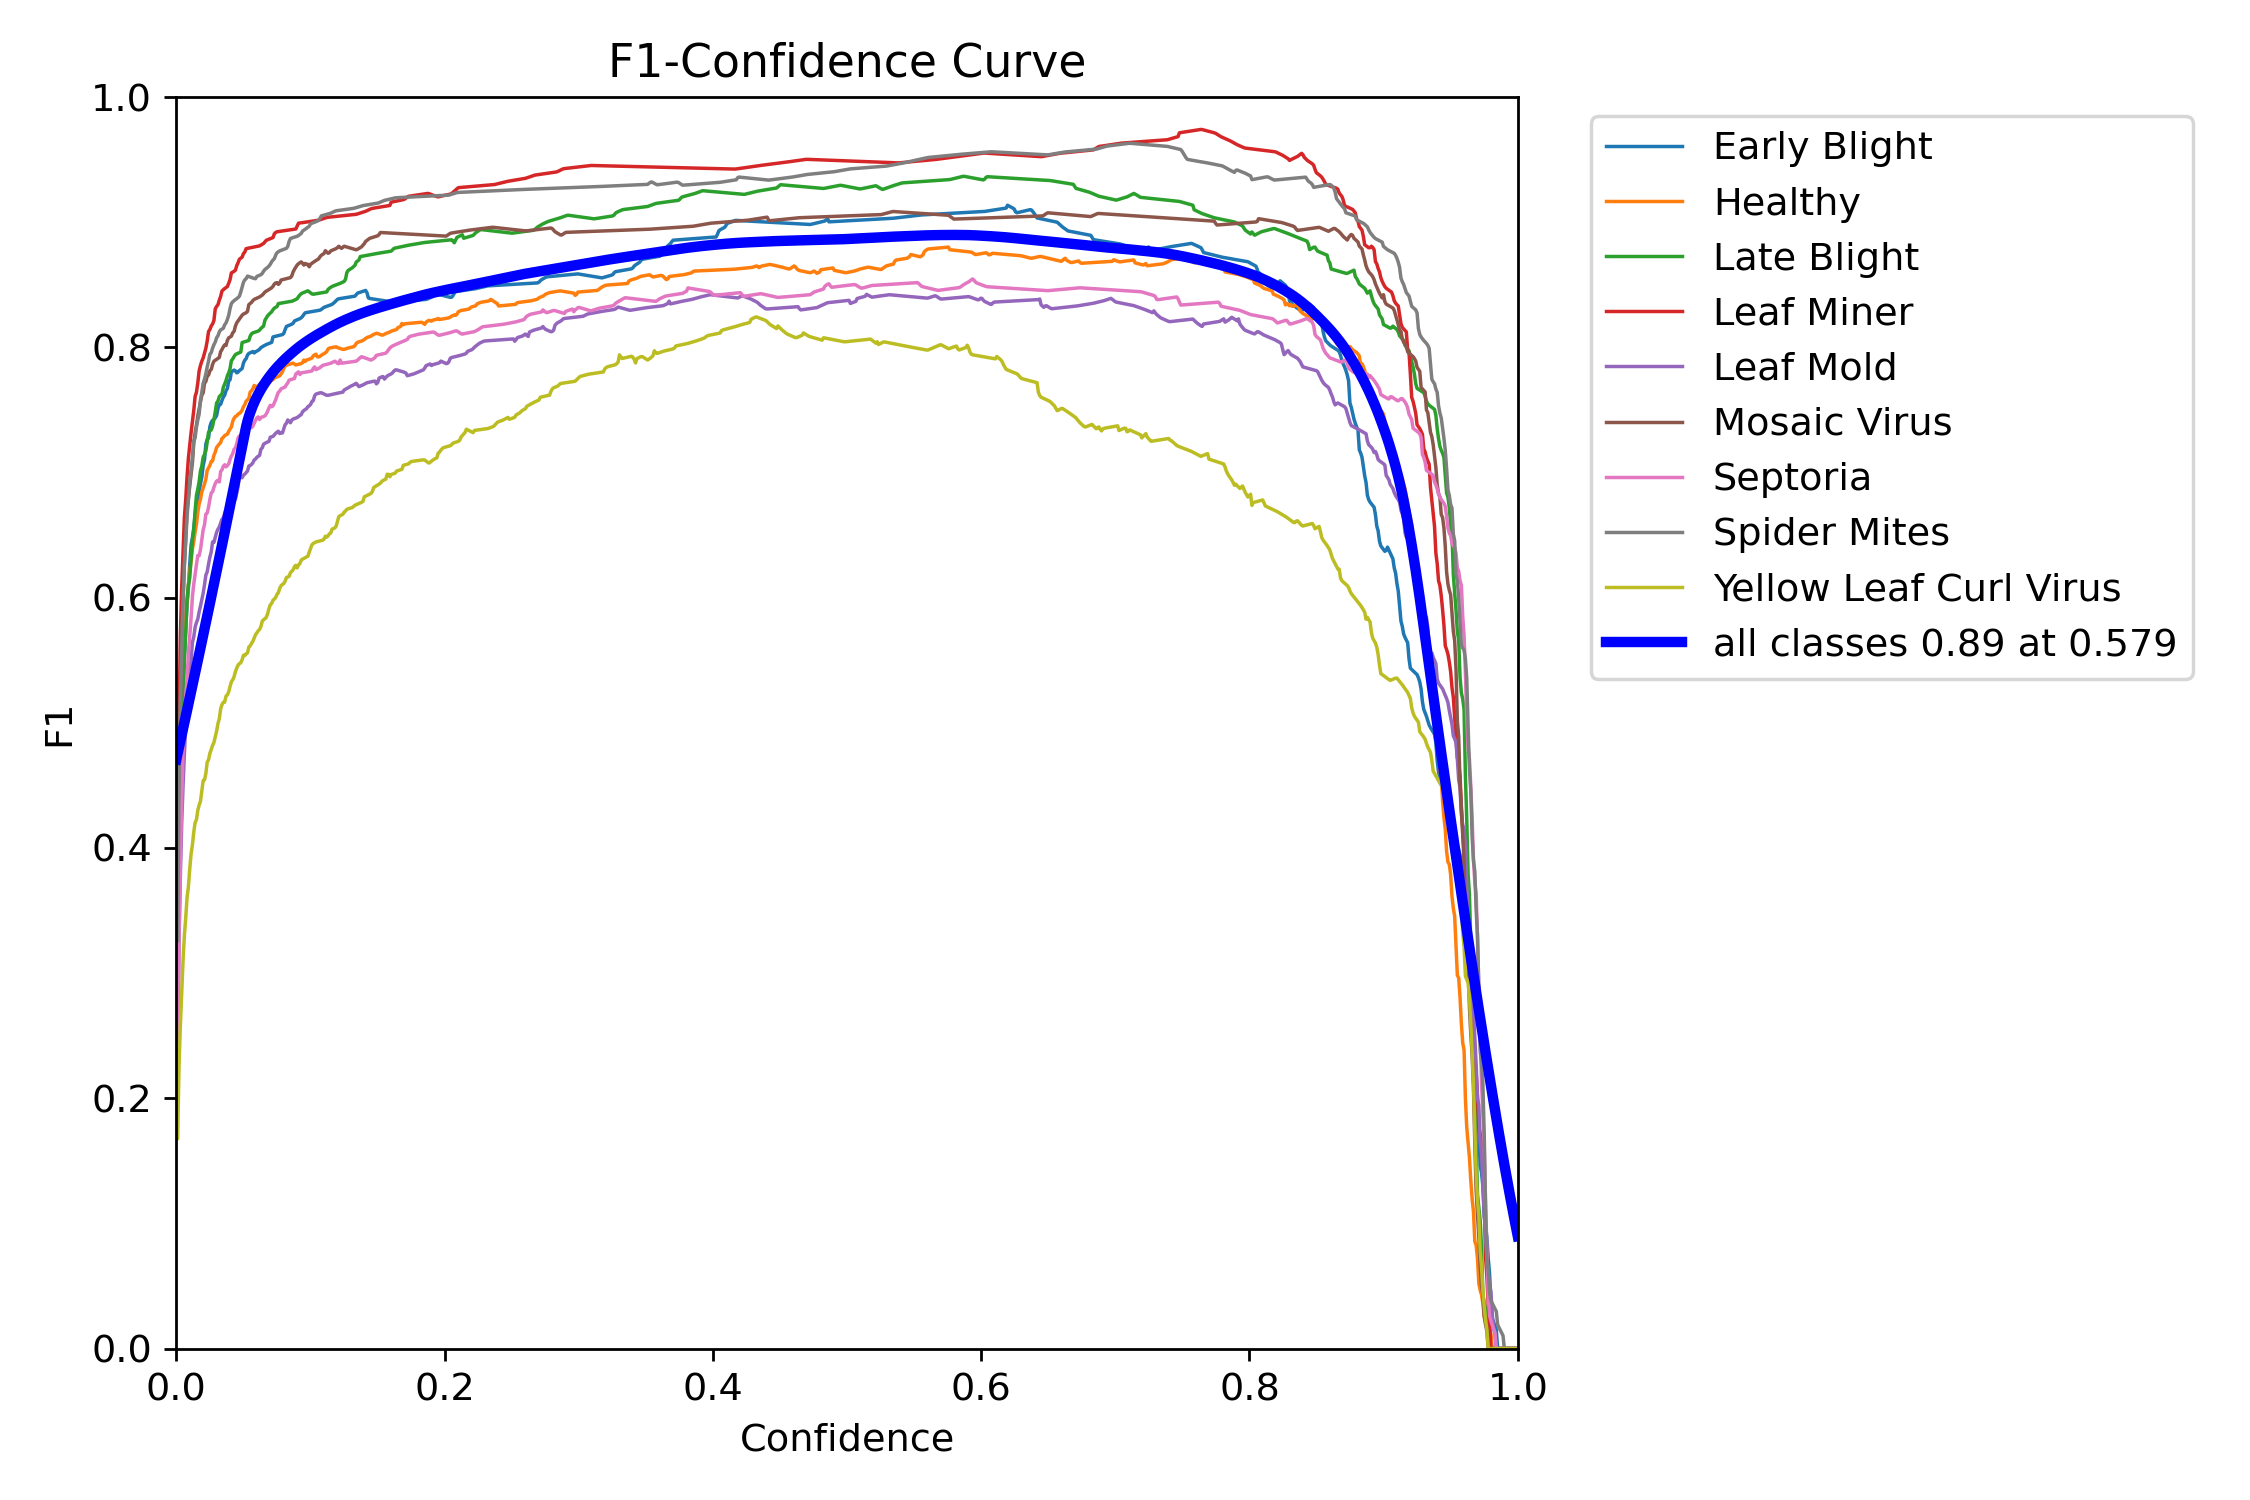

In [ ]:
Image("/content/yolo_runs/tomato_detection/BoxF1_curve.png")

In [ ]:
import pandas as pd

df = pd.read_csv("/content/yolo_runs/tomato_detection/results.csv")

df.tail()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,2803.96,0.43625,0.37207,0.94156,0.89685,0.87722,0.93972,0.83265,0.57164,0.54624,1.01747,0.000084,0.000084,0.000084
46,47,2862.67,0.43395,0.36874,0.93491,0.91236,0.86418,0.93864,0.82924,0.56725,0.54641,1.01601,0.000069,0.000069,0.000069
47,48,2919.64,0.42945,0.35454,0.93562,0.91573,0.86708,0.93961,0.83200,0.56682,0.54314,1.01259,0.000053,0.000053,0.000053
48,49,2976.60,0.42948,0.35565,0.93456,0.90734,0.87751,0.94080,0.83496,0.55916,0.53429,1.00632,0.000038,0.000038,0.000038
49,50,3033.97,0.42638,0.35752,0.93390,0.90818,0.87652,0.94086,0.83771,0.55523,0.52734,1.00254,0.000023,0.000023,0.000023


In [ ]:
from google.colab import files

files.download("/content/yolo_runs/tomato_detection/results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/yolo_runs/tomato_detection/results.csv")

df.to_excel("tomato_detection_results.xlsx", index=False)

In [ ]:
from google.colab import files

files.download("tomato_detection_results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/yolo_runs/tomato_detection/results.csv")

final_results = df.tail(1)

final_results.to_excel("Final_Model_Results.xlsx", index=False)

In [ ]:
from google.colab import files

files.download("Final_Model_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil

save_dir = "/content/drive/MyDrive/Tomato_Detection_Model"
os.makedirs(save_dir, exist_ok=True)

shutil.copy(
    "/content/yolo_runs/tomato_detection/weights/best.pt",
    save_dir + "/tomato_detection.pt"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/yolo_runs/tomato_detection/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

shutil.copy(
    "/content/yolo_runs/tomato_detection/weights/best.pt",
    "/content/tomato_detection.pt"
)

'/content/tomato_detection.pt'

In [ ]:
from google.colab import files

files.download("/content/tomato_detection.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO

model = YOLO("tomato_detection.pt")

print("Model loaded successfully!")

Model loaded successfully!
